## Домашка 2
<h4><em>«Одно Кольцо, чтоб править всеми,<br>
Одно Кольцо, чтоб всех найти,<br>
Одно Кольцо, чтоб собрать всех в тени<br>
И заковать их всех во Тьме»</em><br>
— <em>Властелин колец</em>
</h4>

Эта домашка про приоритизацию метрик. За неё можно получить максимум 12 баллов. 

**Дедлайны**   
Мягкий дедлайн: 27.09.2026 23:59 по МСК.   
Жесткий дедлайн: 04.10.2026 23:59 по МСК.

Штраф за сдачу после мягкого дедлайна: –20% от набранного балла.
После жесткого дедлайна работы не принимаются.

**Правила сдачи**  
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.

**Использование ИИ**

- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_2). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.

Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_2_data.zip)

In [1]:
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

### Warm up

#### 1. Game dev — 2 балла
У вас есть данные о событиях в мобильной игре. Рассчитайте и визуализируйте:
- User Stickiness — отношение DAU к MAU (MAU рассчитывайте скользящим окном 30 дней для каждой даты только для полного окна)
- ARPDAU
- Paying Share — доля платящих пользователей
- Sessions per User — среднее число сессий на пользователя
- Daily Play Time — среднее время, проводимое пользователем в игре в день (рассчитываем как общее время в приложении)
- Avg Attempts per Session — среднее число попыток на сессию

*Смотрим на подневную динамику

In [16]:
df_game = pd.read_csv('data/hw_2_gamedev.csv', index_col=0)
df_game.head()

,session_id,user,date,revenue,attempts,session_length_sec
0,24590322,k0xevcHJ,2022-11-02,NaN,2.0,263
1,24590323,fMaLiagr,2022-11-02,NaN,10.0,953
2,24590324,0EXv0Q2V,2022-11-02,NaN,6.0,630
3,24590325,nY32SwuK,2022-11-02,NaN,9.0,1262
4,24590326,3KZkImTN,2022-11-02,NaN,16.0,2871


Описание данных (уникальный ключ session_id)

- session_id — уникальный идентификатор сессии
- user — уникальный идентификатор юзера
- date — дата 
- revenue — суммарная выручка на сессию
- attempts — число попыток на сессию
- session_length_sec — длина сессии в секундах

In [17]:
df_game['date'] = pd.to_datetime(df_game['date'])

In [18]:
daily = df_game.groupby('date').agg(
    dau=('user', 'nunique'),
    revenue=('revenue', 'sum'),
    sessions=('session_id', 'count'),
    attempts=('attempts', 'sum'),
    play_time=('session_length_sec', 'sum')
)

In [19]:
payers = df_game[df_game['revenue'] > 0].groupby('date')['user'].nunique()
daily['payers'] = payers
daily['payers'] = daily['payers'].fillna(0)

In [20]:
first_date = daily.index.min()

In [21]:
mau = {}
for d in daily.index:
    start = d - timedelta(days=29)
    if start < first_date:
        continue
    mask = (df_game['date'] >= start) & (df_game['date'] <= d)
    mau[d] = df_game[mask]['user'].nunique()
daily['mau'] = pd.Series(mau)

In [22]:
daily['stickiness'] = daily['dau'] / daily['mau']
daily['arpdau'] = daily['revenue'] / daily['dau']
daily['paying_share'] = daily['payers'] / daily['dau']
daily['sessions_per_user'] = daily['sessions'] / daily['dau']
daily['play_time_min'] = daily['play_time'] / daily['dau'] / 60
daily['attempts_per_session'] = daily['attempts'] / daily['sessions']

In [23]:
metrics = {
    'stickiness': 'User Stickiness (DAU / MAU)',
    'arpdau': 'ARPDAU',
    'paying_share': 'Paying Share',
    'sessions_per_user': 'Sessions per User',
    'play_time_min': 'Daily Play Time (мин)',
    'attempts_per_session': 'Avg Attempts per Session'
}

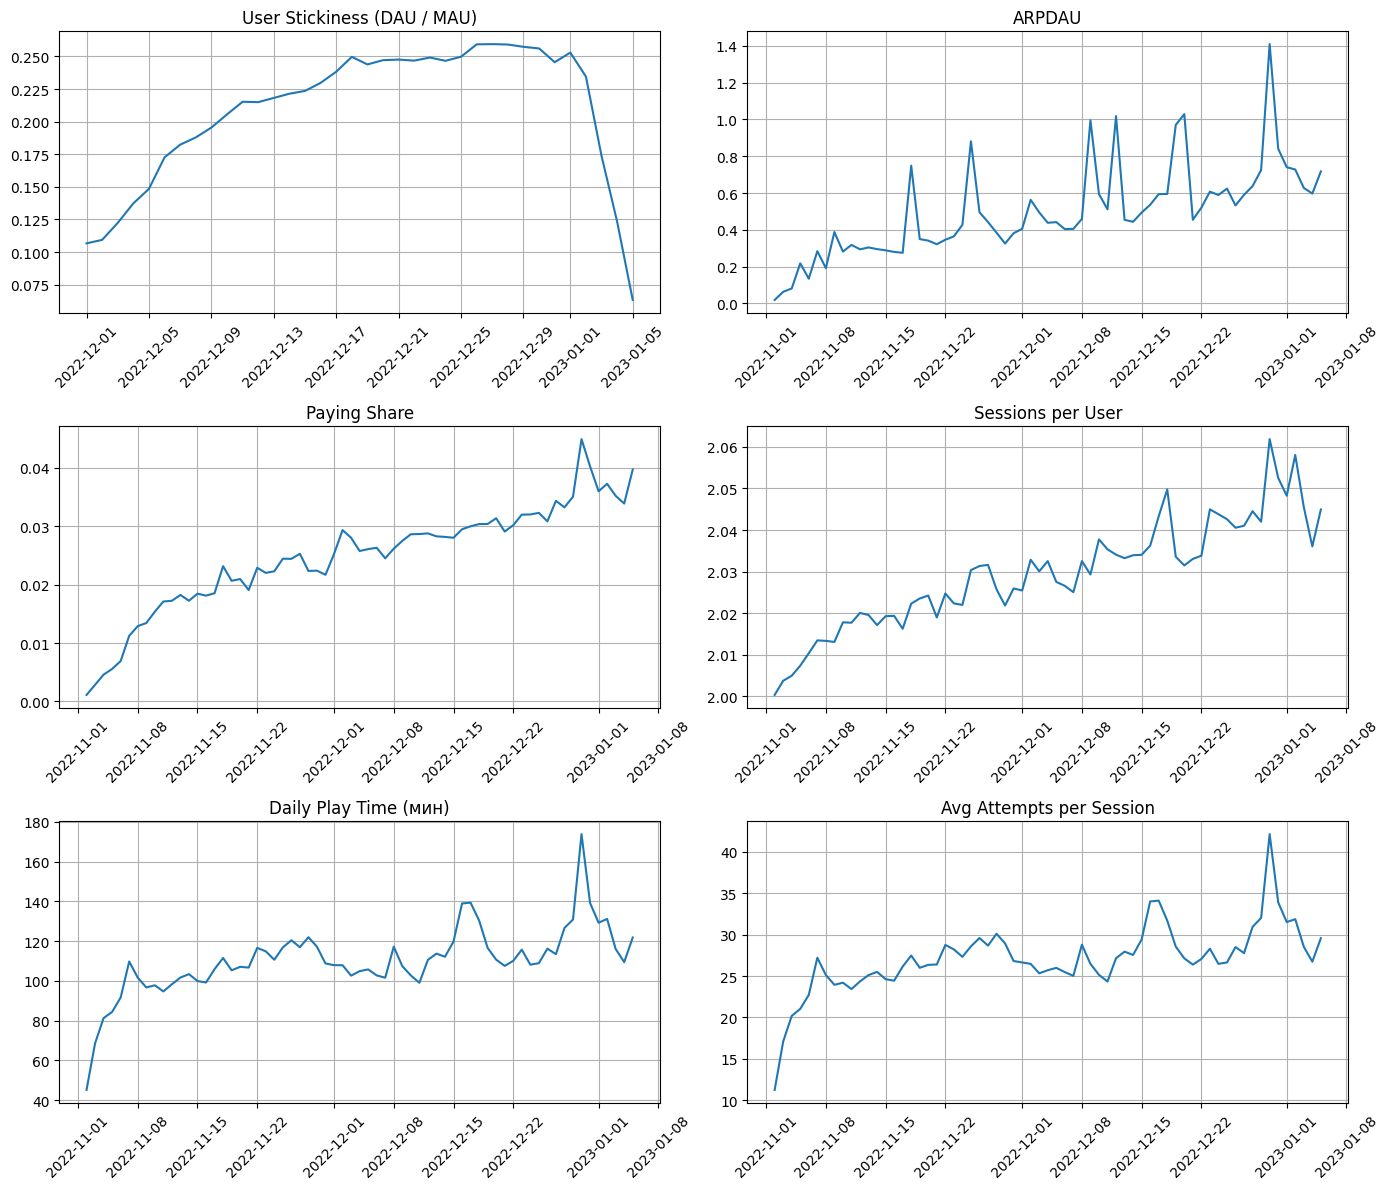

In [24]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, (col, title) in zip(axes.flatten(), metrics.items()):
    ax.plot(daily.index, daily[col])
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True)
plt.tight_layout()
plt.show()

#### 2. Ride hailing  — 2 балла
У вас есть данные из приложения такси. Рассчитайте и визуализируйте:
- Ride Completion Rate — CR из заказа в завершенную поездку
- Acceptance Rate — доля заказов, принятых водителем (считаем, что приняты все заказы, кроме заказов со статусом 'No Driver Found')
- Cancellation Rate — доля отмененных заказов
- Rides per Driver — среднее число поездок на водителя
- Avg Ride Check — средний чек поездки
- Отношение RTA к ETA (что измеряет эта метрика?)

*Смотрим на подневную динамику

In [25]:
df_rh = pd.read_csv('data/hw_2_taxi.csv')

In [26]:
df_rh.head()

,date,time,order_uid,order_status,passenger_id,vehicle_type,pickup_location,drop_location,ETA,RTA,...,reason_for_cancelling_by_customer,cancelled_rides_by_driver,driver_cancellation_reason,incomplete_rides,incomplete_rides_reason,fare,ride_distance,driver_ratings,customer_rating,payment_method
0,2024-01-01,00:19:34,2a11faf27f77eae8,Completed,CID8362794,Bike,Udyog Vihar,Ambience Mall,9.0,10.8,...,NaN,NaN,NaN,NaN,NaN,99.0,37.98,4.8,4.8,Cash
1,2024-01-01,01:35:18,33ed1f6bad78bdc8,Completed,CID8300238,Go Mini,Basai Dhankot,Madipur,6.0,8.5,...,NaN,NaN,NaN,NaN,NaN,114.0,39.29,4.2,4.1,Uber Wallet
2,2024-01-01,01:37:50,e2fc1fc520e93b85,Cancelled by Driver,CID2030746,Go Sedan,Tughlakabad,Greater Kailash,6.0,7.4,...,NaN,1.0,More than permitted people in there,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-01-01,01:48:03,a130fd507acf7804,Cancelled by Driver,CID3231181,Auto,Palam Vihar,Kherki Daula Toll,5.0,NaN,...,NaN,1.0,Personal & Car related issues,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-01-01,01:49:56,cae2db8689a422fa,Cancelled by Driver,CID3381661,Go Sedan,Narsinghpur,Pulbangash,3.0,6.2,...,NaN,1.0,More than permitted people in there,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Описание данных (уникальный ключ order_uid)

- date — дата создания заказа
- time — время создания заказа
- order_uid — уникальный идентификатор заказа
- order_status — статус заказа
- passenger_id — уникальный идентификатор пассажира
- vehicle_type — тип транспорта 
- pickup_location — место отправления
- drop_location — место назначения
- ETA — прогнозное время прибытия водителя на место отправления (estimated time of arrival)
- RTA — реальное время прибытия водителя на место отправления (real time of arrival)
- driver_id — уникальный идентификатор водителя
- cancelled_rides_by_customer — флаг отмены поездки пассажиром
- reason_for_cancelling_by_customer — причина отмены поездки пассажиром
- cancelled_rides_by_driver — флаг отмены поездки водителем
- driver_cancellation_reason — причина отмены поездки водителем
- incomplete_rides — флаг незавершенной поездки
- incomplete_rides_reason — причина незавершенной поездки
- fare — цена поездки
- ride_distance – расстояние поездки
- driver_ratings — рейтинг водителя
- customer_rating — рейтинг пассажира
- payment_method – способ оплаты

In [27]:
df_rh['date'] = pd.to_datetime(df_rh['date'])
df_rh['order_status'].value_counts()

order_status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64

In [28]:
g = df_rh.groupby('date')
daily = pd.DataFrame()
daily['orders'] = g['order_uid'].count()
daily['completed'] = df_rh[df_rh['order_status'] == 'Completed'].groupby('date')['order_uid'].count()
daily['accepted'] = df_rh[df_rh['order_status'] != 'No Driver Found'].groupby('date')['order_uid'].count()
daily['cancelled'] = df_rh[df_rh['order_status'].isin(['Cancelled by Customer', 'Cancelled by Driver'])].groupby('date')['order_uid'].count()
daily['drivers'] = df_rh[df_rh['order_status'] == 'Completed'].groupby('date')['driver_id'].nunique()
daily['avg_check'] = df_rh[df_rh['order_status'] == 'Completed'].groupby('date')['fare'].mean()

In [29]:
eta_rta = df_rh.dropna(subset=['ETA', 'RTA']).groupby('date')[['ETA', 'RTA']].mean()
daily['rta_eta'] = eta_rta['RTA'] / eta_rta['ETA']

In [30]:
daily = daily.fillna(0)
daily['completion_rate'] = daily['completed'] / daily['orders']
daily['acceptance_rate'] = daily['accepted'] / daily['orders']
daily['cancellation_rate'] = daily['cancelled'] / daily['orders']
daily['rides_per_driver'] = daily['completed'] / daily['drivers']

In [31]:
metrics = {
    'completion_rate': 'Ride Completion Rate',
    'acceptance_rate': 'Acceptance Rate',
    'cancellation_rate': 'Cancellation Rate',
    'rides_per_driver': 'Rides per Driver',
    'avg_check': 'Avg Ride Check',
    'rta_eta': 'RTA / ETA'
}

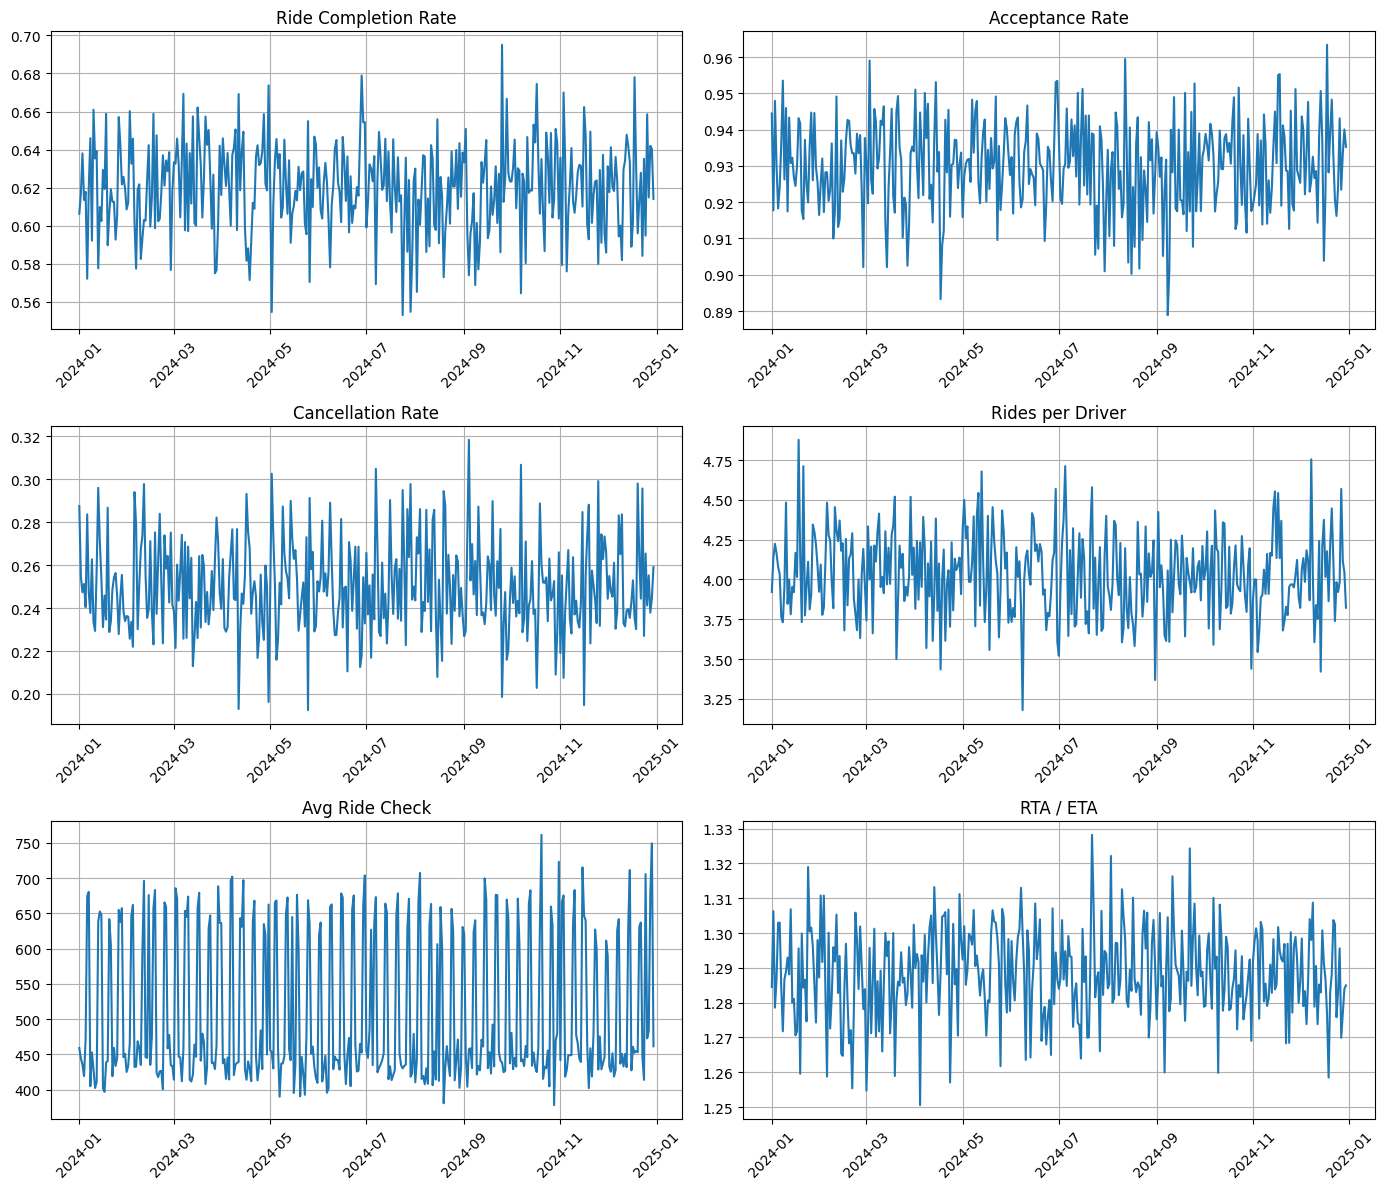

In [32]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, (col, title) in zip(axes.flatten(), metrics.items()):
    ax.plot(daily.index, daily[col])
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True)
plt.tight_layout()
plt.show()

### Case Study. Запуск подкастов в стриминговом сервисе 🎧

**Легенда**  
Вы работаете продуктовым аналитиком в музыкальном стриминговом сервисе. Недавно в продукте запустился раздел с подкастами. Команда, отвечающая за запуск, хочет понять, стоит ли масштабировать и продвигать этот формат.

In [33]:
df_music_logs = pd.read_parquet('data/hw_2_streaming_logs.pqt')
df_music_subs = pd.read_parquet('data/hw_2_streaming_subs.pqt')

In [34]:
df_music_logs.head()

,datetime,uid,item_id,played_ratio_pct,track_length_seconds,content_type,is_first_date
0,2024-01-13 10:00:00,468300,7400764,100,225,music,0.0
1,2024-01-13 10:00:05,347600,3415205,100,250,music,0.0
2,2024-01-13 10:00:10,942900,6728180,1,270,music,0.0
3,2024-01-13 10:00:15,243500,5283544,100,195,music,0.0
4,2024-01-13 10:00:15,12700,8932363,100,245,music,0.0


In [35]:
df_music_subs.head()

,uid,start_date,end_date
0,600,2024-08-08,NaT
1,700,2024-03-29,NaT
2,800,2024-06-13,NaT
3,1100,2024-11-19,NaT
4,1400,2024-12-01,NaT


Описание данных hw_2_streaming_logs:

- datetime — дата-время взаимодействия с контентом
- uid — уникальный идентификатор пользователя
- item_id — уникальный идентификатор трека/эпизода
- played_ratio_pct — процент от длительности, который был воспроизведен
- track_length_seconds – длина трека/эпизода в секундах
- content_type — тип контента: музыка или подкаст
- is_first_date — флаг, является ли эта дата первой для пользователя в продукте

Описание данных hw_2_streaming_subs:

- uid — уникальный идентификатор пользователя
- start_date — дата начала подписки
- end_date — дата окончания подписки

#### 3. Метрики роста  — 2 балла

Рассчитайте и визуализируйте:
- DAU, MAU, WAU;
- Количество новых премиум-подписчиков (за неделю и месяц);
- Проникновение подкастов — долю юзеров, послушавших подкаст хотя бы раз (за неделю и месяц).

Сделайте выводы:
- Есть ли выраженный тренд?
- Нет ли подозрений, что с раскаткой раздела что-то могло пойти не так (изменение тренда, выраженные ступеньки)?
- Как выглядит адопшен? Можно ли предположить наличие каких-то эффектов в пользовательском взаимодействии с новым разделом?

In [36]:
df_music_logs['datetime'] = pd.to_datetime(df_music_logs['datetime'])
df_music_logs['date'] = df_music_logs['datetime'].dt.normalize()
df_music_subs['start_date'] = pd.to_datetime(df_music_subs['start_date'])
df_music_logs['content_type'].value_counts()

content_type
music      46325679
podcast       58861
Name: count, dtype: int64

In [37]:
dau = df_music_logs.groupby('date')['uid'].nunique()
first_date = dau.index.min()

In [38]:
def rolling_users(days):
    res = {}
    for d in dau.index:
        start = d - timedelta(days=days - 1)
        if start < first_date:
            continue
        mask = (df_music_logs['date'] >= start) & (df_music_logs['date'] <= d)
        res[d] = df_music_logs[mask]['uid'].nunique()
    return pd.Series(res)

In [39]:
wau = rolling_users(7)
mau = rolling_users(30)

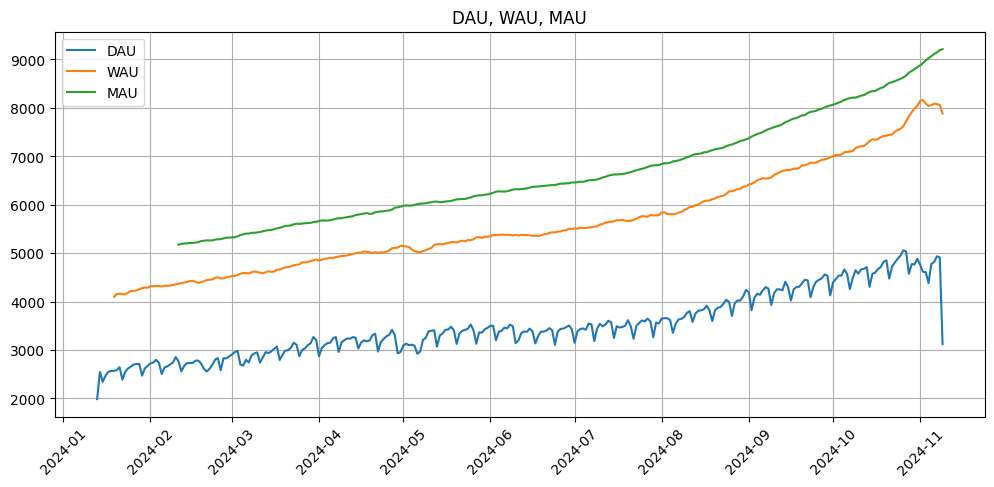

In [40]:
plt.figure(figsize=(12, 5))
plt.plot(dau.index, dau, label='DAU')
plt.plot(wau.index, wau, label='WAU')
plt.plot(mau.index, mau, label='MAU')
plt.title('DAU, WAU, MAU')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

In [41]:
first_sub = df_music_subs.groupby('uid')['start_date'].min()
new_week = first_sub.groupby(first_sub.dt.to_period('W').dt.start_time).count()
new_month = first_sub.groupby(first_sub.dt.to_period('M').dt.start_time).count()

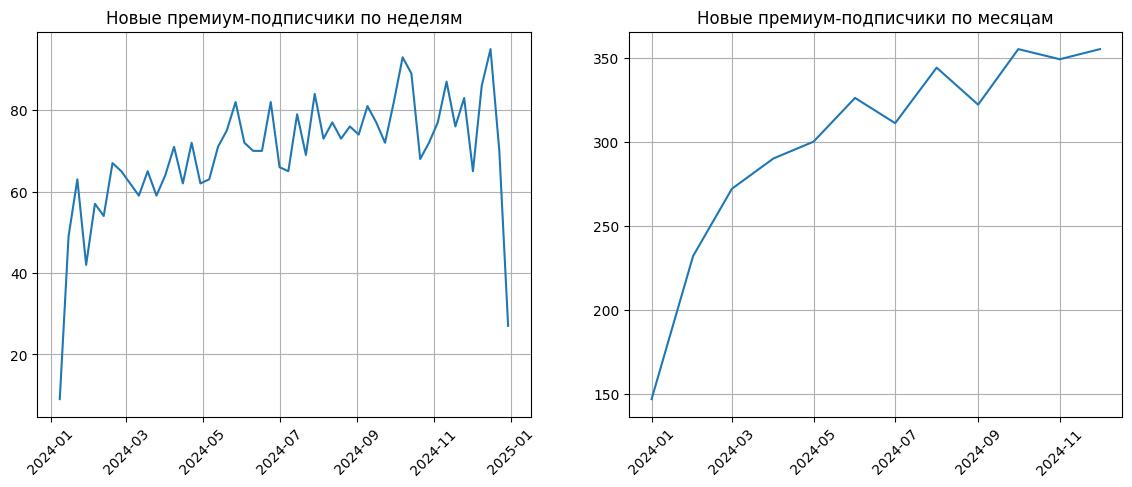

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(new_week.index, new_week)
axes[0].set_title('Новые премиум-подписчики по неделям')
axes[1].plot(new_month.index, new_month)
axes[1].set_title('Новые премиум-подписчики по месяцам')
for ax in axes:
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)
plt.show()

In [43]:
df_music_logs['week'] = df_music_logs['date'].dt.to_period('W').dt.start_time
df_music_logs['month'] = df_music_logs['date'].dt.to_period('M').dt.start_time

In [44]:
def penetration(col):
    all_users = df_music_logs.groupby(col)['uid'].nunique()
    pod_users = df_music_logs[df_music_logs['content_type'] == 'podcast'].groupby(col)['uid'].nunique()
    return (pod_users / all_users).fillna(0)

In [45]:
pen_week = penetration('week')
pen_month = penetration('month')

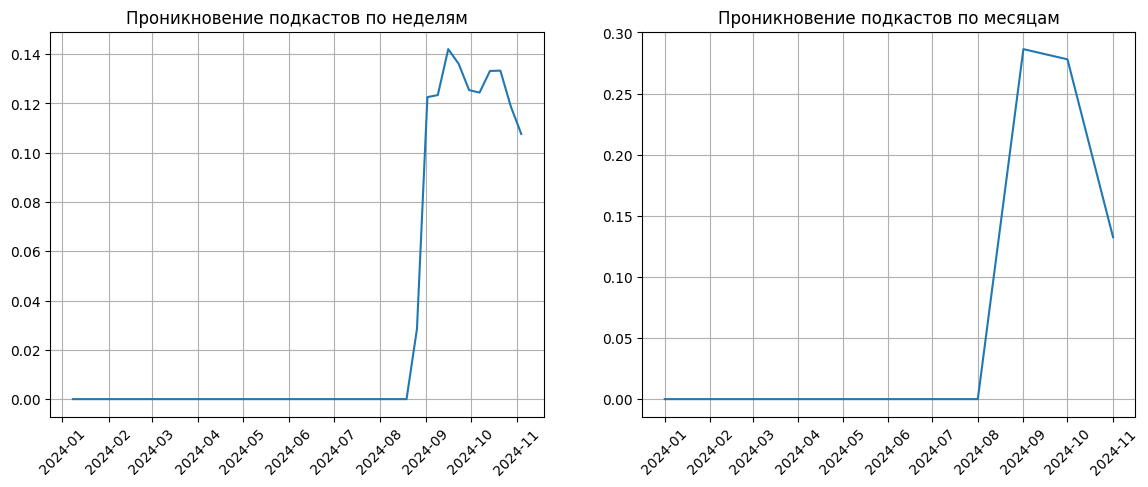

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(pen_week.index, pen_week)
axes[0].set_title('Проникновение подкастов по неделям')
axes[1].plot(pen_month.index, pen_month)
axes[1].set_title('Проникновение подкастов по месяцам')
for ax in axes:
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)
plt.show()

#### Тренд

Рост выраженный: DAU с 2000 до 5000, MAU с 5200 до 9200, есть недельная сезонность. Новые подписчики растут, потом выходят на плато (около 80 в неделю, 350 в месяц). Рост начался задолго до подкастов.

#### Раскатка

Ступенек в момент запуска нет, тренд почти не изменился. Падения в конце графиков (последний день DAU, последняя неделя подписчиков, ноябрь в проникновении) это неполные периоды, а не реальные события.

#### Адопшен

Проникновение подкастов резко выросло с 0 до 12% в неделю в конце августа, потом снизилось до 11%. Месячное около 28%, заметно выше недельного. Многие попробовали, но регулярно слушает меньшая часть. Похоже на эффект новизны. Подкастов в логах очень мало (58 тысяч событий против 46 миллионов у музыки). На метрики роста они пока почти не влияют.

#### 4. Метрики продукта (шаг 1)  — 2 балла

Рассчитайте и визуализируйте как для всех пользователей в совокупности, так и для сегментов пользователей в разрезе — сделали / не сделали взаимодействие с подкастами (грубо говоря разделяем юзеров на тех, кто слушает только музыку и тех, кто слушает еще и подкасты):
1. Среднее время прослушивания на пользователя.
2. Среднее число треков/эпизодов на пользователя (среднее число item_id). Посчитайте метрику, как от уникальных, так и от не уникальных item_id. Подумайте, что показывает каждая из них?
3. Долю премиум-подписчиков. Обратите внимание, что нам нужна активная подписка, если пользователь отписался в том же периоде, что подписался, мы больше не считаем подписку активной.

Рассчитайте и визуализируйте как по всем item_id, так и в разрезе типов контента:
- Долю дослушанных треков/эпизодов до конца. Обратите внимание, данная метрика уже не пользовательская.

Периоды — неделя и месяц. Неполные периоды нужно обрезать, если они мешают чтению графиков.   
Признак взаимодействия присвайвайте только для периода, когда оно действительно было.   
Для месячной динамики метрик по признаку взаимодействия с подкастами у вас получится всего 2 точки, такая визуализая тоже полезна, она сглаживает недельные колебания и помогает оценивать тренд в масштабе года.

Сделайте выводы:
- Есть ли выраженный тренд?
- Изменилась ли метрика после запуска подкастов?
- Отличается ли метрика сегмента, взаимодействовавшего с подкастами, от тех, кто слушал только музыку? (будьте аккуратны с выводами в этом пункте, мы не проверяем изменение на каузальность, поэтому не можем быть уверены где причина, а где следствие)
- Есть ли отличия между типами контента?

*За взаимодействие с подкастами давайте считать только прослушивание >= 30% или более 2х минут контента*

In [47]:
df = df_music_logs
df['date'] = df['datetime'].dt.normalize()
df['week'] = df['date'].dt.to_period('W').dt.start_time
df['month'] = df['date'].dt.to_period('M').dt.start_time
df_music_subs['end_date'] = pd.to_datetime(df_music_subs['end_date'])

df['played_ratio_pct'].describe()

count    4.638454e+07
mean     6.478661e+01
std      4.408013e+01
min      0.000000e+00
25%      7.000000e+00
50%      1.000000e+02
75%      1.000000e+02
max      1.590000e+02
Name: played_ratio_pct, dtype: float64

In [48]:
df['listen_sec'] = df['played_ratio_pct'] / 100 * df['track_length_seconds']
df['finished'] = df['played_ratio_pct'] >= 100
df['pod_touch'] = (df['content_type'] == 'podcast') & ((df['played_ratio_pct'] >= 30) | (df['listen_sec'] > 120))

In [49]:
min_date = df['date'].min()
max_date = df['date'].max() - pd.Timedelta(days=1)

week_ends = {p: p + pd.Timedelta(days=6) for p in df['week'].drop_duplicates()}
week_ends = {p: e for p, e in week_ends.items() if p >= min_date and e <= max_date}
month_ends = {p: p + pd.offsets.MonthEnd(0) for p in df['month'].drop_duplicates()}
month_ends = {p: e for p, e in month_ends.items() if p >= min_date and e <= max_date}

In [50]:
def get_active(ends):
    res = {}
    for p, e in ends.items():
        s = df_music_subs
        a = s[(s['start_date'] <= e) & (s['end_date'].isna() | (s['end_date'] > e))]
        res[p] = set(a['uid'])
    return res

In [51]:
def make_table(col, ends):
    d = df[df[col].isin(list(ends.keys()))]
    u = d.groupby([col, 'uid']).agg(
        listen_sec=('listen_sec', 'sum'),
        tracks=('item_id', 'count'),
        uniq_tracks=('item_id', 'nunique'),
        pod=('pod_touch', 'max')
    ).reset_index()
    u['minutes'] = u['listen_sec'] / 60
    active = get_active(ends)
    u['premium'] = [uid in active[p] for uid, p in zip(u['uid'], u[col])]
    u['premium'] = u['premium'].astype(int)
    return u

In [52]:
cols = ['minutes', 'tracks', 'uniq_tracks', 'premium']

In [53]:
def summarize(u, col):
    res = {}
    res['all'] = u.groupby(col)[cols].mean()
    res['pod'] = u[u['pod']].groupby(col)[cols].mean()
    res['music'] = u[~u['pod']].groupby(col)[cols].mean()
    return res

In [54]:
week_res = summarize(make_table('week', week_ends), 'week')
month_res = summarize(make_table('month', month_ends), 'month')

In [55]:
titles = {
    'minutes': 'Среднее время прослушивания на пользователя (мин)',
    'tracks': 'Среднее число item_id (не уникальные)',
    'uniq_tracks': 'Среднее число item_id (уникальные)',
    'premium': 'Доля премиум-подписчиков'
}

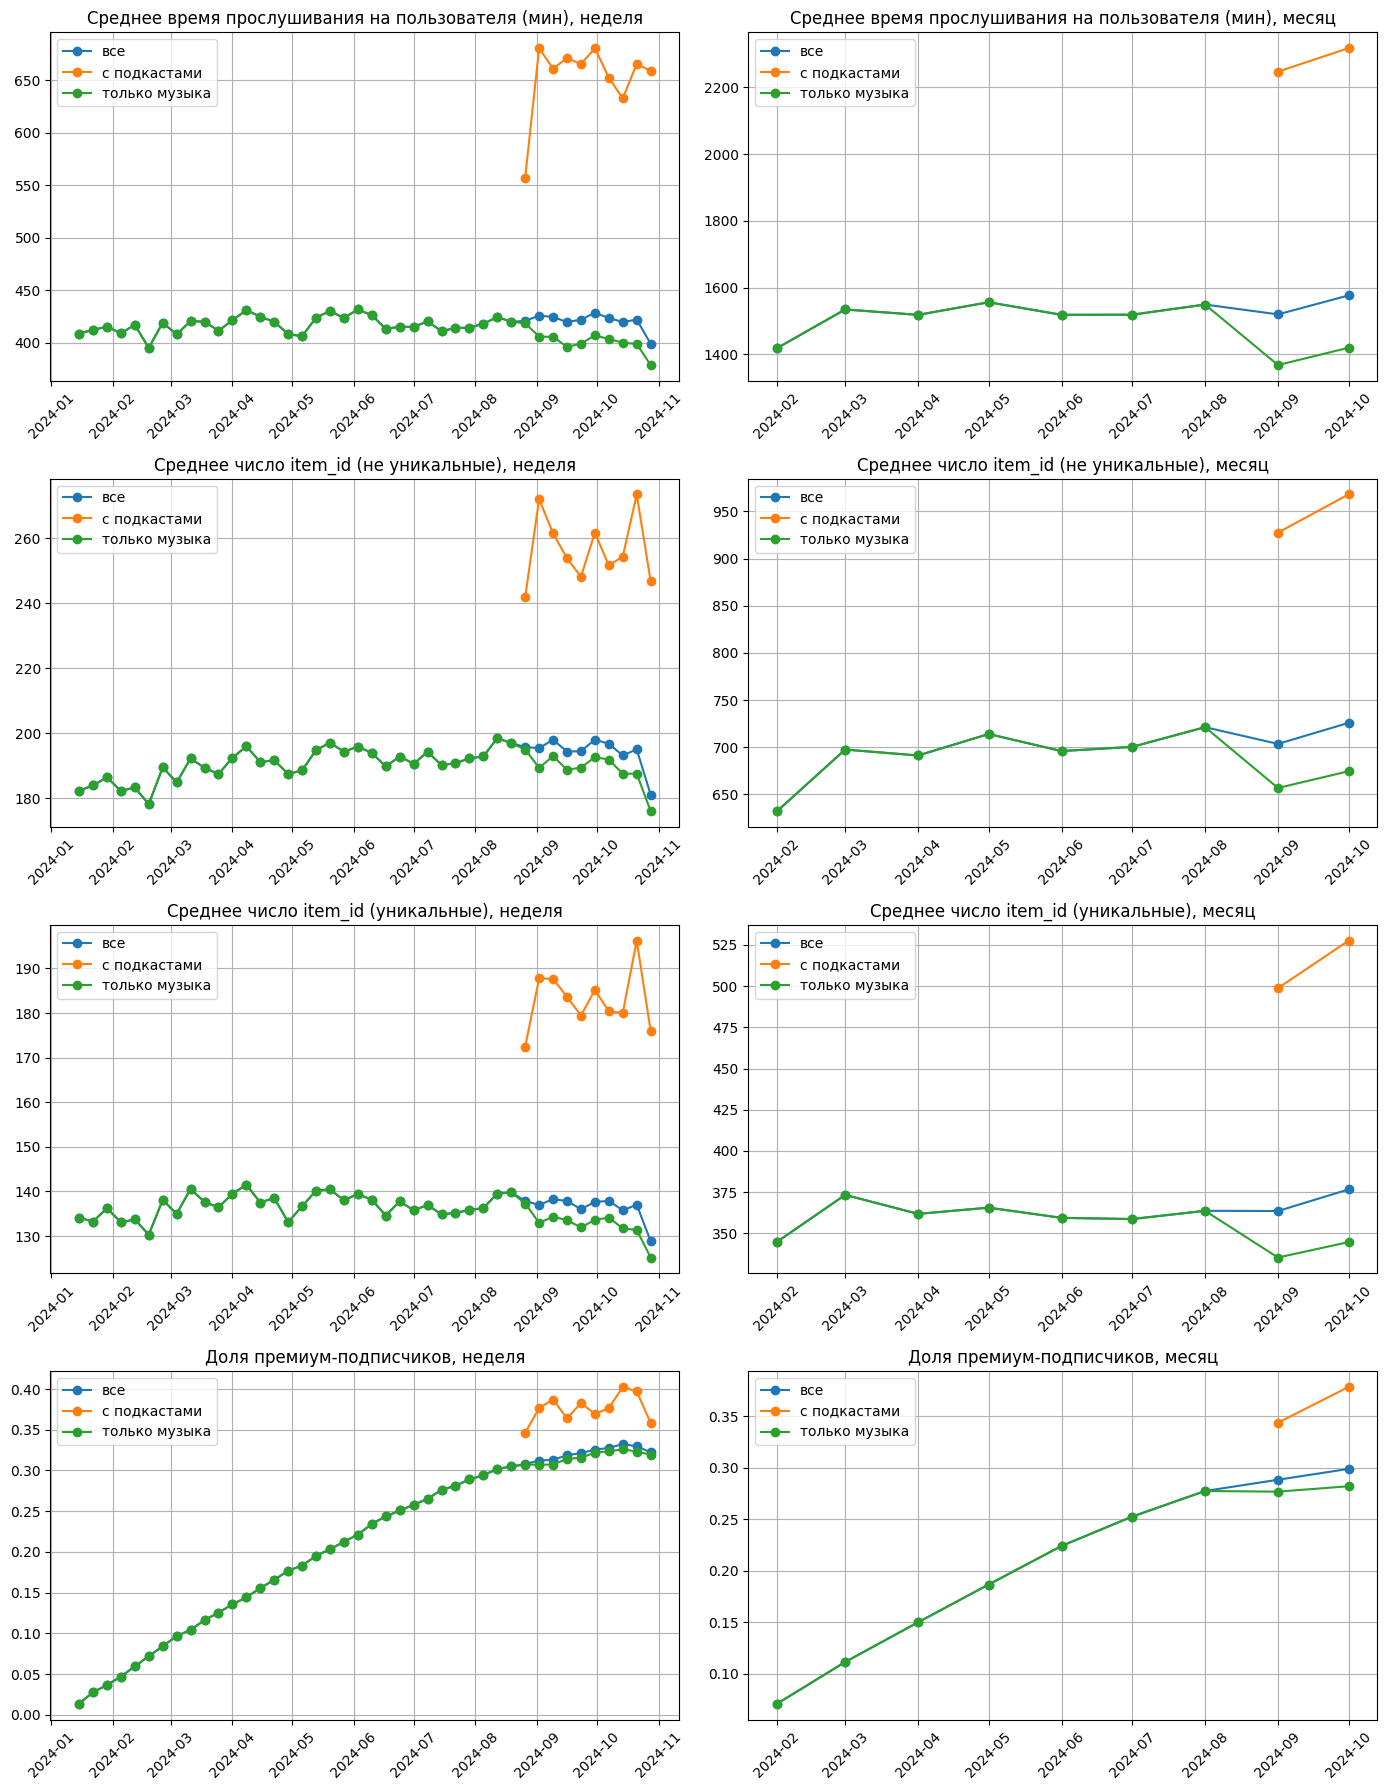

In [56]:
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for i, c in enumerate(cols):
    for j, (res, name) in enumerate([(week_res, 'неделя'), (month_res, 'месяц')]):
        ax = axes[i, j]
        ax.plot(res['all'].index, res['all'][c], marker='o', label='все')
        ax.plot(res['pod'].index, res['pod'][c], marker='o', label='с подкастами')
        ax.plot(res['music'].index, res['music'][c], marker='o', label='только музыка')
        ax.set_title(titles[c] + ', ' + name)
        ax.legend()
        ax.grid(True)
        ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [57]:
def finish_table(col, ends):
    d = df[df[col].isin(list(ends.keys()))]
    res = d.groupby([col, 'content_type'])['finished'].mean().unstack()
    res['all'] = d.groupby(col)['finished'].mean()
    return res

In [58]:
fin_week = finish_table('week', week_ends)
fin_month = finish_table('month', month_ends)

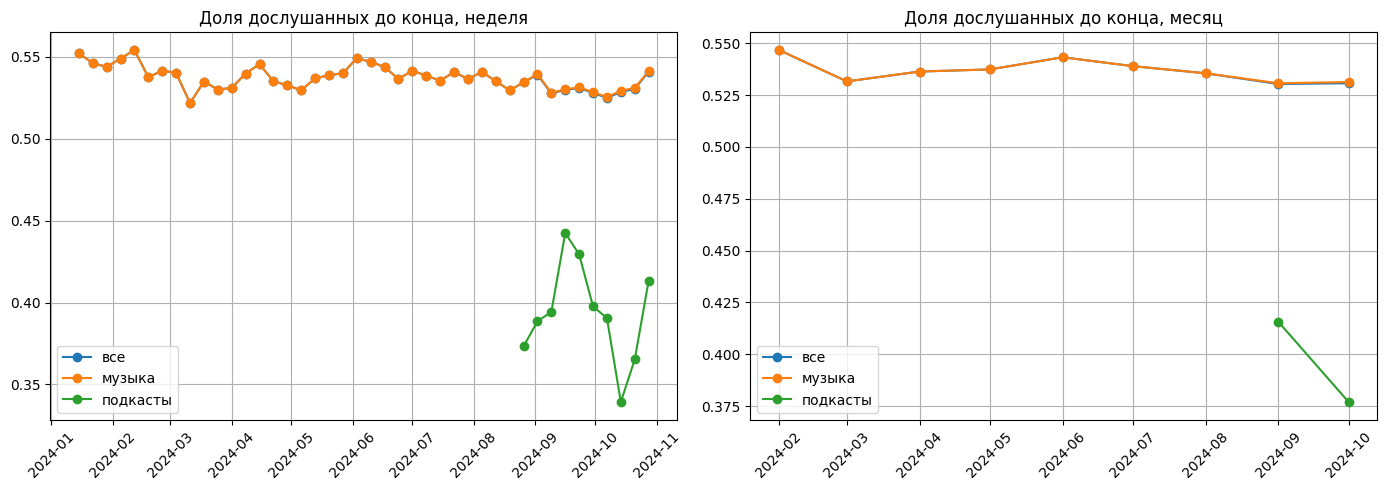

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, res, name in zip(axes, [fin_week, fin_month], ['неделя', 'месяц']):
    ax.plot(res.index, res['all'], marker='o', label='все')
    ax.plot(res.index, res['music'], marker='o', label='музыка')
    ax.plot(res.index, res['podcast'], marker='o', label='подкасты')
    ax.set_title('Доля дослушанных до конца, ' + name)
    ax.legend()
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

#### Тренд

По времени прослушивания и числу item_id тренда почти нет, метрики держатся на одном уровне (около 410-430 минут и 190 треков в неделю). Доля премиум-подписчиков растет с 0 до 33%, но с августа рост замедляется и выходит на плато. Доля дослушанных до конца по музыке стабильна, около 53-54%.

#### После запуска подкастов

Заметных изменений в общих метриках нет: ни ступеньки, ни смены тренда. Плато по премиуму началось еще до запуска, так что подкасты тут ни при чем. Видно только небольшое расхождение "всех" и "только музыки": у сегмента "только музыка" метрики чуть просели, потому что самые активные пользователи ушли в сегмент с подкастами.

#### Сегменты

Слушатели подкастов заметно активнее: время на пользователя примерно 660 против 400 минут в неделю, item_id 250-270 против 190, уникальных 180-190 против 135, доля премиума 37-40% против 32%. Причинно-следственную связь тут делать нельзя. Скорее всего, подкасты пробуют те, кто и так много слушает и чаще платит.

#### Типы контента

Подкасты дослушивают заметно реже музыки: около 38-42% против 53%. Недельная кривая по подкастам шумная из-за малого числа событий, а месячная падает с 41% до 38%. Похоже, интерес к новинке спадает.

#### 5. Метрики продукта (шаг 2)  — 2 балла

Рассчитайте и визуализируйте:
1) D1, D7, D30 retention по всем пользователям. Когорты агрегируйте по неделям т.к. из-за низкого числа новичков на дневном разрезе визуализации слишком шумные.
2) D30 retention для сегментов пользователей в разрезе — сделали / не сделали взаимодействие с подкастами на промежутке до 30 дня. Когорты агрегируйте по неделям.
3) D7 retention для сегментов пользователей в разрезе — сделали / не сделали взаимодействие с подкастами на промежутке до 7 дня. Когорты агрегируйте по месяцам.

Для наглядности будет полезно нарисовать на одном графике как посегментную, так и общую динамику (для этого можете достроить D7 retention для всех пользователей с помесячной агрегацией).

Сделайте выводы: 
- Есть ли выраженный тренд?
- Изменилась ли метрика после запуска подкастов?
- Отличается ли метрика сегмента, взаимодействовавшего с подкастами, от тех, кто слушал только музыку? (будьте аккуратны с выводами в этом пункте, мы не проверяем изменение на каузальность, поэтому не можем быть уверены где причина, а где следствие)

*За взаимодействие с подкастами давайте считать только прослушивание >= 30% или более 2х минут контента*

In [60]:
max_date = df['date'].max() - pd.Timedelta(days=1)

first = df[df['is_first_date'] == 1].groupby('uid')['date'].min().rename('first_date').reset_index()
users = first.copy()
users['week'] = users['first_date'].dt.to_period('W').dt.start_time
users['month'] = users['first_date'].dt.to_period('M').dt.start_time
users['week_end'] = users['week'] + pd.Timedelta(days=6)
users['month_end'] = users['month'] + pd.offsets.MonthEnd(0)

In [61]:
act = df[['uid', 'date']].drop_duplicates().merge(first, on='uid')
act['day'] = (act['date'] - act['first_date']).dt.days

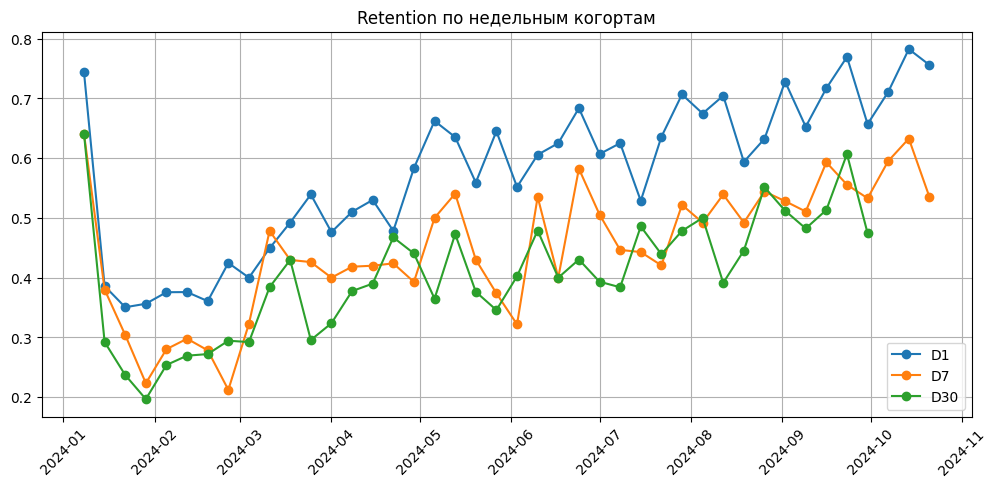

In [62]:
for n in [1, 7, 30]:
    back = act.loc[act['day'] == n, 'uid']
    users['d' + str(n)] = users['uid'].isin(back).astype(int)

plt.figure(figsize=(12, 5))
for n in [1, 7, 30]:
    u = users[users['week_end'] + pd.Timedelta(days=n) <= max_date]
    r = u.groupby('week')['d' + str(n)].mean()
    plt.plot(r.index, r, marker='o', label='D' + str(n))
plt.title('Retention по недельным когортам')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

In [63]:
pod_days = df.loc[df['pod_touch'], ['uid', 'date']].merge(first, on='uid')
pod_days['day'] = (pod_days['date'] - pod_days['first_date']).dt.days

In [64]:
def segments(n, period):
    u = users[users[period + '_end'] + pd.Timedelta(days=n) <= max_date].copy()
    pod_uids = pod_days.loc[pod_days['day'] <= n, 'uid'].unique()
    u['pod'] = u['uid'].isin(pod_uids)
    seg = u.groupby([period, 'pod'])['d' + str(n)].mean().unstack()
    total = u.groupby(period)['d' + str(n)].mean()
    size = u.groupby([period, 'pod']).size().unstack()
    return seg, total, size

In [65]:
seg30, total30, size30 = segments(30, 'week')
seg7, total7, size7 = segments(7, 'month')
size30.tail(10)

pod,False,True
week,,
2024-07-29,91.0,1.0
2024-08-05,117.0,9.0
2024-08-12,107.0,8.0
2024-08-19,108.0,20.0
2024-08-26,103.0,33.0
2024-09-02,96.0,29.0
2024-09-09,114.0,27.0
2024-09-16,85.0,28.0
2024-09-23,88.0,29.0


In [66]:
size7

pod,False,True
month,,
2024-01-01,484.0,NaN
2024-02-01,681.0,NaN
2024-03-01,572.0,NaN
2024-04-01,425.0,NaN
2024-05-01,369.0,NaN
2024-06-01,350.0,NaN
2024-07-01,419.0,NaN
2024-08-01,535.0,5.0
2024-09-01,453.0,79.0


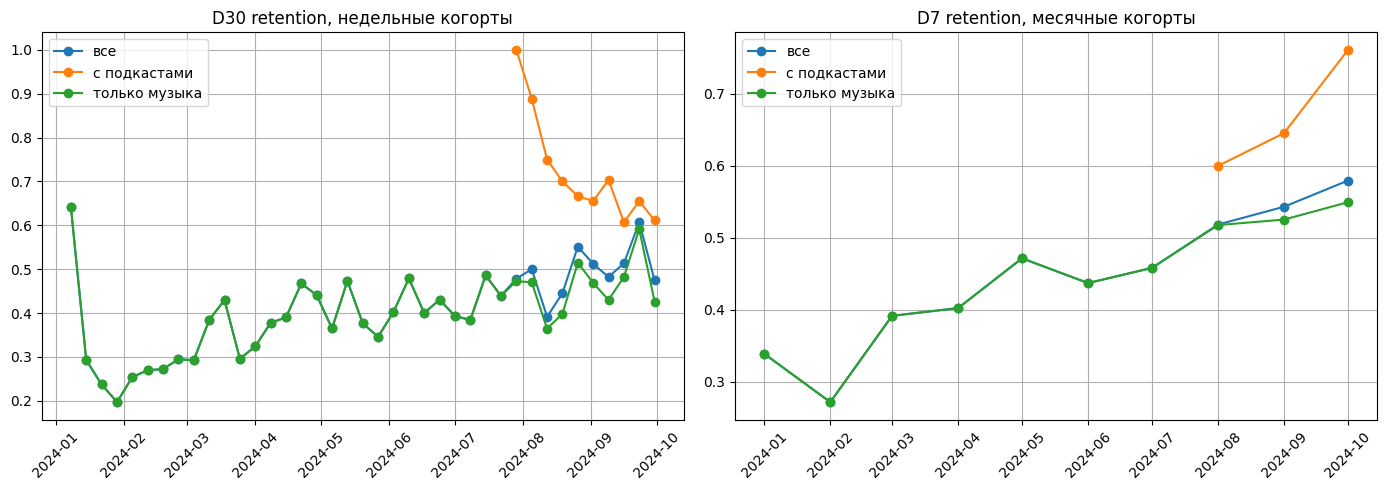

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(total30.index, total30, marker='o', label='все')
axes[0].plot(seg30.index, seg30[True], marker='o', label='с подкастами')
axes[0].plot(seg30.index, seg30[False], marker='o', label='только музыка')
axes[0].set_title('D30 retention, недельные когорты')

axes[1].plot(total7.index, total7, marker='o', label='все')
axes[1].plot(seg7.index, seg7[True], marker='o', label='с подкастами')
axes[1].plot(seg7.index, seg7[False], marker='o', label='только музыка')
axes[1].set_title('D7 retention, месячные когорты')

for ax in axes:
    ax.legend()
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

#### Тренд

Выраженный рост по всем метрикам. D1 вырос с 0.35-0.4 в январе до 0.75 в октябре, D7 с 0.2-0.3 до 0.5-0.6, D30 с 0.2 до 0.5. Самая первая когорта (начало января) с высокими значениями похожа на артефакт данных, ее лучше не учитывать. Недельные точки шумные, но общий рост виден.

#### После запуска подкастов

Ступеньки нет, рост шел и до запуска. Месячный D7 по всем пользователям растет плавно: 0.52 в августе, 0.54 в сентябре, 0.58 в октябре. Это продолжение прежнего тренда, эффект подкастов тут не отделить.

#### Сегменты

У пользователей с подкастами retention выше. D30 около 0.6-0.7 против 0.4-0.5 у "только музыка". D7 по месяцам 0.60, 0.65 и 0.76 против 0.52-0.55. Но выводы аккуратные:

Чтобы попасть в сегмент с подкастами, надо вернуться в продукт и послушать подкаст. Поэтому retention там выше почти автоматически.
Группа маленькая: около 30 человек в неделю и 70-80 в месяц. В августе было всего 5 человек, точка не показательна. Первые точки D30 (1.0, 0.9) это 1-9 человек.
Возможно, подкасты пробуют те, кто и так вовлечен.

#### Вывод

Cвязь есть, но причину установить нельзя. Что подкасты повышают retention, по этим данным не доказано.

#### 6. Приоритизация метрик  — 2 балла

Составьте список всех метрик, которые были рассчитаны выше (не забудьте, что показатель, рассчитанный в разрезе сегмента — это отдельная метрика). Для простоты давайте ориентироваться только на недельную агрегацию.

1. Присвойте метрикам приоритеты P0-P3 по принципу (в этом пункте стройте приоритизацию на уровне всей компании):
   -  P0 — бизнес результат;
   -  P1 — метрики продукта, напрямую аффектящие бизнес-результат (retention, product as a habit);
   -  P2 — метрики, отражающие взаимодействие пользователя с продуктом (user experience, user engagement) / таргет-метрики отдельных команд продукта;
   -  P3 — метрики стримов / опыт пользователя в рамках работы отдельных команд.
2. Пересоберите приоритеты только для команды подкастов, если цель развития подкастов — рост пользователей с подпиской. Обратите внимание, что вам не нужно отказываться от метрик, рассчитанных по всем пользователям (без сегментов) или для сегмента Music (полезно понимать, не каннибализируем ли мы основной тип контента). Скорее всего приоритеты изменятся только для посегментных метрик.
4. Представьте, что цель внедрения подкастов поменялась — теперь команда в первую очередь хочет задрайвить вовлеченность в продукт. Пересоберите приоритеты при необходимости (в данном пункте могут измениться приоритеты для метрик, рассчитанных по всем пользователям).

Для каждого из пунктов дайте краткое обоснование, почему вы присвоили приоритеты именно так.

1. Уровень компании

- P0: доля премиум и новые подписчики. Это прямой источник денег в подписочном сервисе.
- P1: WAU, MAU, D7 и D30 retention. Они напрямую влияют на подписки: чем больше людей возвращаются, тем больше конвертируются в платящих.
- P2: DAU, D1, время, число item_id, доля дослушанных. Это вовлеченность и качество опыта, но деньги они дают не напрямую.
- P3: все посегментные метрики и проникновение подкастов. Это метрики одной команды, для компании подкасты пока малая доля (58 тысяч событий против 46 миллионов).

2. Команда подкастов, цель: рост числа пользователей с подпиской

- Общие метрики остаются как есть, меняются в основном сегментные.
- Доля премиум в сегменте подкастов становится P0: это прямое измерение цели.
- Доля премиум в сегменте музыки P1: с ней сравниваем и проверяем, что подкасты не каннибализируют основной контент.
- D30 retention подкастного сегмента P1: подписка держится на возвращении.
- Проникновение подкастов P2 (это воронка к цели), дослушиваемость подкастов P2 (качество контента).
- Время и retention сегмента музыки P2, чтобы следить за каннибализацией.

3. Цель: вовлеченность

- Общие метрики по подпискам (доля премиум, новые подписчики) падают до P2, они больше не цель.
- P0: время на пользователя и WAU. Это прямое измерение вовлеченности и регулярности.
- DAU и число item_id (не уник.) поднимаются до P1. Пользоваться регулярно и слушать больше это и есть вовлеченность.
- Проникновение подкастов P1: показывает, доходит ли новый формат до аудитории.
- Время в сегментах P1. У подкастного сегмента это цель, у музыкального нужно следить, чтобы время на музыку не падало.
- Метрики по премиум в сегментах падают до P3.